In [1]:
import copy
import random
import time
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets
import matplotlib.pyplot as plt

SEED = 0
EPOCHS = 8
BATCH_SIZE = 128
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
print("Urządzenie:", DEVICE)

Urządzenie: cuda


In [2]:
mean, std = 0.2860, 0.3530
full_plain = datasets.FashionMNIST("./data", train=True, download=True)
test_raw = datasets.FashionMNIST("./data", train=False, download=True)

generator = torch.Generator().manual_seed(SEED)
train_ids, val_ids = [], []
for label in range(10):
    ids = torch.where(full_plain.targets == label)[0]
    ids = ids[torch.randperm(len(ids), generator=generator)]
    val_ids.extend(ids[:1000].tolist())
    train_ids.extend(ids[1000:].tolist())

train_images = ((full_plain.data[train_ids].float() / 255.0 - mean) / std).unsqueeze(1)
val_images = ((full_plain.data[val_ids].float() / 255.0 - mean) / std).unsqueeze(1)
test_images = ((test_raw.data.float() / 255.0 - mean) / std).unsqueeze(1)
train_plain = TensorDataset(train_images, full_plain.targets[train_ids])
val_ds = TensorDataset(val_images, full_plain.targets[val_ids])
test_ds = TensorDataset(test_images, test_raw.targets)
train_eval_dl = DataLoader(train_plain, batch_size=512, shuffle=False)
val_dl = DataLoader(val_ds, batch_size=512, shuffle=False)
test_dl = DataLoader(test_ds, batch_size=512, shuffle=False)

def training_loader():
    return DataLoader(train_plain, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=DEVICE == "cuda")

print("Trening:", len(train_plain), "Walidacja:", len(val_ds), "Test:", len(test_ds))

100%|██████████| 26.4M/26.4M [00:00<00:00, 115MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 4.41MB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 67.5MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 11.9MB/s]


Trening: 50000 Walidacja: 10000 Test: 10000


In [3]:
class MLP(nn.Module):
    def __init__(self, use_bn=False, p_drop=0.0):
        super().__init__()
        layers = [nn.Flatten()]
        previous = 28 * 28
        for current in (256, 128):
            layers.append(nn.Linear(previous, current))
            if use_bn:
                layers.append(nn.BatchNorm1d(current))
            layers.append(nn.ReLU())
            if p_drop:
                layers.append(nn.Dropout(p_drop))
            previous = current
        layers.append(nn.Linear(previous, 10))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

def evaluate(model, loader):
    model.eval()
    loss_sum, correct, total = 0.0, 0, 0
    criterion = nn.CrossEntropyLoss(reduction="sum")
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            outputs = model(images)
            loss_sum += criterion(outputs, labels).item()
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return loss_sum / total, correct / total

In [4]:
def run_experiment(config):
    torch.manual_seed(SEED)
    model = MLP(config.get("bn", False), config.get("dropout", 0.0)).to(DEVICE)
    loader = training_loader()
    if config.get("adamw", False):
        optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)
    else:
        optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_state, best_epoch, best_acc, best_loss = None, 0, -1.0, float("inf")
    started = time.perf_counter()
    for epoch in range(1, EPOCHS + 1):
        model.train()
        for images, labels in loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            if config.get("augment", False):
                images = images.clone()
                flip_mask = torch.rand(images.size(0), device=DEVICE) < 0.5
                images[flip_mask] = torch.flip(images[flip_mask], dims=(-1,))
            optimizer.zero_grad()
            loss = criterion(model(images), labels)
            loss.backward()
            optimizer.step()
        tr_loss, tr_acc = evaluate(model, train_eval_dl)
        va_loss, va_acc = evaluate(model, val_dl)
        for key, value in zip(history, (tr_loss, va_loss, tr_acc, va_acc)):
            history[key].append(value)
        if va_acc > best_acc or (va_acc == best_acc and va_loss < best_loss):
            best_state = copy.deepcopy(model.state_dict())
            best_epoch, best_acc, best_loss = epoch, va_acc, va_loss
        print(f"{config['name']:18s} | epoka {epoch:2d}/{EPOCHS} | train {tr_acc*100:5.2f}% | val {va_acc*100:5.2f}% | val loss {va_loss:.3f}")
    model.load_state_dict(best_state)
    tr_loss, tr_acc = evaluate(model, train_eval_dl)
    va_loss, va_acc = evaluate(model, val_dl)
    return {"config": config, "model": model, "history": history, "epoch": best_epoch, "train_loss": tr_loss, "train_acc": tr_acc, "val_loss": va_loss, "val_acc": va_acc, "gap": va_loss - tr_loss, "seconds": time.perf_counter() - started}

configs = [
    {"name": "Baseline"},
    {"name": "Dropout 0.2", "dropout": 0.2},
    {"name": "BatchNorm", "bn": True},
    {"name": "AdamW WD=0.01", "adamw": True},
    {"name": "Flip 0.5", "augment": True},
    {"name": "BN+Dropout+AdamW", "bn": True, "dropout": 0.2, "adamw": True},
]

results = [run_experiment(config) for config in configs]

Baseline           | epoka  1/8 | train 86.71% | val 86.31% | val loss 0.384
Baseline           | epoka  2/8 | train 88.87% | val 87.45% | val loss 0.342
Baseline           | epoka  3/8 | train 89.53% | val 87.90% | val loss 0.331
Baseline           | epoka  4/8 | train 90.27% | val 88.50% | val loss 0.318
Baseline           | epoka  5/8 | train 90.36% | val 88.49% | val loss 0.321
Baseline           | epoka  6/8 | train 89.58% | val 87.03% | val loss 0.348
Baseline           | epoka  7/8 | train 91.89% | val 88.81% | val loss 0.306
Baseline           | epoka  8/8 | train 92.14% | val 88.87% | val loss 0.318
Dropout 0.2        | epoka  1/8 | train 85.92% | val 85.07% | val loss 0.401
Dropout 0.2        | epoka  2/8 | train 88.17% | val 87.36% | val loss 0.354
Dropout 0.2        | epoka  3/8 | train 88.03% | val 86.59% | val loss 0.358
Dropout 0.2        | epoka  4/8 | train 88.75% | val 87.35% | val loss 0.342
Dropout 0.2        | epoka  5/8 | train 89.84% | val 88.11% | val loss 0.325

In [5]:
print(f"{'Wariant':20s} {'Epoka':>5s} {'Val acc':>9s} {'Train acc':>10s} {'Luka straty':>12s} {'Czas':>8s}")
for r in results:
    print(f"{r['config']['name']:20s} {r['epoch']:5d} {r['val_acc']*100:8.2f}% {r['train_acc']*100:9.2f}% {r['gap']:12.4f} {r['seconds']:7.1f}s")

baseline = results[0]
best = max(results, key=lambda r: (r["val_acc"], -r["val_loss"]))
print("Wybrany wariant:", best["config"]["name"])

Wariant              Epoka   Val acc  Train acc  Luka straty     Czas
Baseline                 8    88.87%     92.14%       0.1081    13.3s
Dropout 0.2              8    89.05%     91.22%       0.0704    13.8s
BatchNorm                8    89.42%     93.82%       0.1321    14.2s
AdamW WD=0.01            8    89.12%     92.31%       0.1090    12.6s
Flip 0.5                 8    88.83%     91.06%       0.0772    14.4s
BN+Dropout+AdamW         5    89.31%     91.14%       0.0621    14.2s
Wybrany wariant: BatchNorm


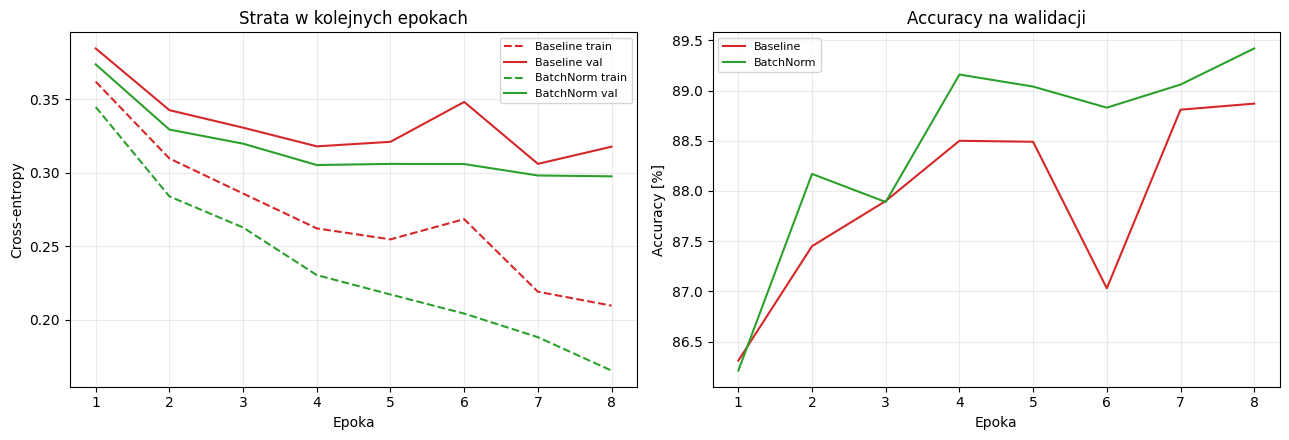

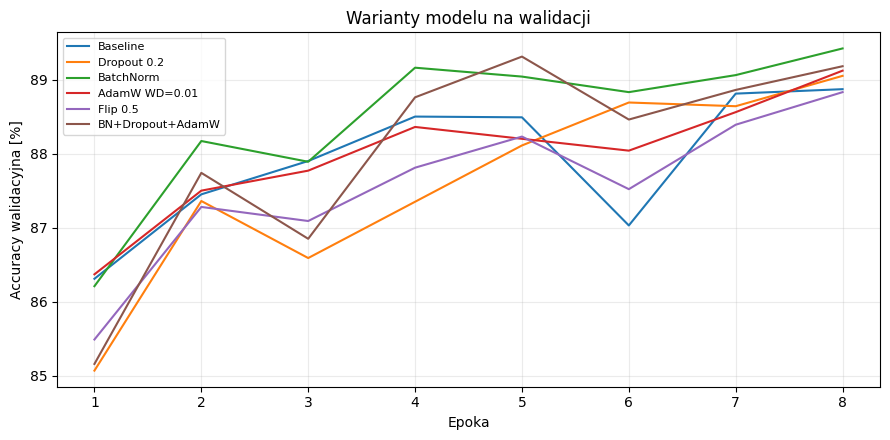

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for r, color in ((baseline, "tab:red"), (best, "tab:green")):
    epochs = range(1, EPOCHS + 1)
    axes[0].plot(epochs, r["history"]["train_loss"], linestyle="--", color=color, label=r["config"]["name"] + " train")
    axes[0].plot(epochs, r["history"]["val_loss"], color=color, label=r["config"]["name"] + " val")
    axes[1].plot(epochs, [a * 100 for a in r["history"]["val_acc"]], color=color, label=r["config"]["name"])
axes[0].set(title="Strata w kolejnych epokach", xlabel="Epoka", ylabel="Cross-entropy")
axes[1].set(title="Accuracy na walidacji", xlabel="Epoka", ylabel="Accuracy [%]")
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 4.5))
for r in results:
    plt.plot(range(1, EPOCHS + 1), [a * 100 for a in r["history"]["val_acc"]], label=r["config"]["name"])
plt.xlabel("Epoka")
plt.ylabel("Accuracy walidacyjna [%]")
plt.title("Warianty modelu na walidacji")
plt.grid(alpha=0.25)
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [7]:
base_test_loss, base_test_acc = evaluate(baseline["model"], test_dl)
best_test_loss, best_test_acc = evaluate(best["model"], test_dl)
print(f"Baseline: test accuracy = {base_test_acc * 100:.2f}%, test loss = {base_test_loss:.4f}")
print(f"{best['config']['name']}: test accuracy = {best_test_acc * 100:.2f}%, test loss = {best_test_loss:.4f}")
print(f"Baseline: luka walidacja-trening = {baseline['gap']:.4f}")
print(f"Wybrany wariant: luka walidacja-trening = {best['gap']:.4f}")
print(f"Baseline: luka test-trening = {base_test_loss - baseline['train_loss']:.4f}")
print(f"Wybrany wariant: luka test-trening = {best_test_loss - best['train_loss']:.4f}")
print(f"Różnica accuracy testowej = {(best_test_acc - base_test_acc) * 100:+.2f} p.p.")

Baseline: test accuracy = 88.09%, test loss = 0.3406
BatchNorm: test accuracy = 88.61%, test loss = 0.3251
Baseline: luka walidacja-trening = 0.1081
Wybrany wariant: luka walidacja-trening = 0.1321
Baseline: luka test-trening = 0.1311
Wybrany wariant: luka test-trening = 0.1597
Różnica accuracy testowej = +0.52 p.p.
